# 3. Probability-probability (PP) tests

If the likelihood and the prior are right, the true value of a parameter lies below the $p$ credible level of its
posterior in a fraction $p$ of the injections: the PP curve follows the diagonal.

`exmarg.pp` draws injections from the prior of the analysis, each in its own noise, analyzes every segment with the
tables (`exmarg.search`), and returns the credible level of every true parameter. The injections and the analysis use the
same prior: the intrinsic parameters uniform in their box, isotropic sky and orientation, uniform phase and arrival time over
the segment, and the Madau--Dickinson distance prior of the simulated year (`exmarg.priors`), which gives the injections the
SNRs of a real population.

This notebook writes the result files of Fig. 19 (`../data/results/pp_3p.npz`, `pp_2p.npz`) and draws the figure from them.

In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
import exmarg
import exmarg.pp
import exmarg.search as search
import figures_validation as figures

exmarg.detectors.set_curve('o4_gw250207')
start = time.time()
store = search.load_redshift_store('../tables/redshift', pinned=True)
print('tables read in %.0f s' % (time.time() - start))

tables read in 31 s


## Three parameters

300 injections uniform in the detector-frame total mass from 20 to $200\,M_\odot$, the mass ratio from 0.3 to 1 and the
spin from $-0.6$ to $0.6$ (the prior of Fig. 20), in segments of 4 s. The posterior of each is computed on a grid of
$40 \times 24 \times 20$ points in $(M_{\rm det}, q, \chi)$ with the distance integrated over its prior, and the credible
level of the chirp mass comes from posterior samples spread over the cells of the grid.

In [2]:
start = time.time()
levels = exmarg.pp.run_intrinsic(store, 300, device='gpu')
print('300 injections in %.0f min' % ((time.time() - start) / 60))
print('network SNR of the injections: median %.1f, 90th percentile %.1f, largest %.1f'
      % (np.median(levels[:, 3]), np.percentile(levels[:, 3], 90), levels[:, 3].max()))
np.savez('../data/results/pp_3p.npz', cred_Mc=levels[:, 0], cred_q=levels[:, 1], cred_chi=levels[:, 2], snr=levels[:, 3])

300 injections in 153 min
network SNR of the injections: median 1.1, 90th percentile 3.7, largest 22.6


## Two parameters

592 equal-mass binaries without spin, uniform in the detector-frame total mass from 20 to $200\,M_\odot$, in segments of
8 s, analyzed with the distance as a parameter (`search.pe_redshift`) on the bank of 3,517 masses; the posterior on the grid of
$(m_1^{\rm src}, z)$ is the likelihood ratio times the same prior.

In [3]:
start = time.time()
levels = exmarg.pp.run_redshift(store, 592, np.load('../data/banks/two_parameters.npy'), device='gpu')
print('592 injections in %.0f min' % ((time.time() - start) / 60))
print('network SNR of the injections: median %.1f, 90th percentile %.1f, largest %.1f'
      % (np.median(levels[:, 2]), np.percentile(levels[:, 2], 90), levels[:, 2].max()))
np.savez('../data/results/pp_2p.npz', cred_m1=levels[:, 0], cred_z=levels[:, 1], snr=levels[:, 2])

592 injections in 141 min
network SNR of the injections: median 1.2, 90th percentile 4.2, largest 36.3


## Fig. 19 of the paper

Left: $(\mathcal{M}_c, q, \chi_{\rm eff})$ for the 300 injections. Right: $(m_1^{\rm src}, z)$ for the 592 injections.

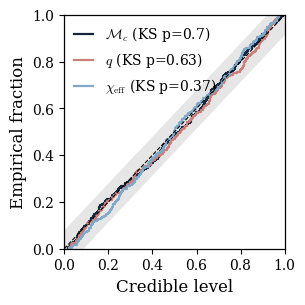

In [4]:
figures.fig_pp_3p(np.load('../data/results/pp_3p.npz'))

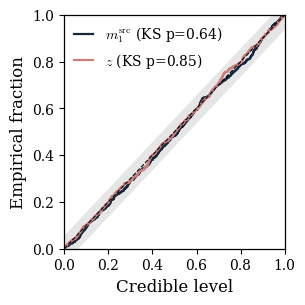

In [5]:
figures.fig_pp_2p(np.load('../data/results/pp_2p.npz'))